# Energy Analyst Programming Exercise
Tasks are completed one at a time. Task 4 uses polars for speed; everything else uses pandas.

## Configuration
System-specific parameters live here.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl

EXERCISE_DIR = Path("energyanalystcodingexercise/energyanalystcodingexercise-6be9efb8b8fd7beb0ad7236a5a956dc369c2fb5b")
HISTORICAL_DIR = EXERCISE_DIR / "historicalPriceData"
SUPPLEMENTAL_DIR = EXERCISE_DIR / "supplementalMaterials"
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

## Task 1: Read and combine the historical data

In [2]:
files = sorted(HISTORICAL_DIR.glob("*.csv"))
prices = pd.concat(
    (pd.read_csv(f, parse_dates=["Date"]) for f in files),
    ignore_index=True,
)
print(f"Read {len(files)} files -> {len(prices):,} rows")

# pandas hides the time component when every row in the preview is midnight, so format it explicitly
# and show 30 consecutive hours for one settlement point.
preview = prices[prices["SettlementPoint"] == "HB_NORTH"].head(30).copy()
preview["Date"] = preview["Date"].dt.strftime("%Y-%m-%d %H:%M:%S")
preview

Read 4 files -> 497,320 rows


,Date,SettlementPoint,Price
3,2016-01-01 00:00:00,HB_NORTH,18.43
17,2016-01-01 01:00:00,HB_NORTH,16.17
31,2016-01-01 02:00:00,HB_NORTH,15.64
45,2016-01-01 03:00:00,HB_NORTH,15.65
59,2016-01-01 04:00:00,HB_NORTH,15.97
73,2016-01-01 05:00:00,HB_NORTH,16.74
87,2016-01-01 06:00:00,HB_NORTH,18.98
101,2016-01-01 07:00:00,HB_NORTH,19.19
115,2016-01-01 08:00:00,HB_NORTH,19.10
129,2016-01-01 09:00:00,HB_NORTH,19.69


### Sanity checks

In [3]:
print(prices.dtypes, "", sep="\n")
print("Missing values:", prices.isna().sum(), "", sep="\n")
print("Date range:", prices["Date"].min(), "to", prices["Date"].max())
print("Settlement points:", prices["SettlementPoint"].nunique())
print("Duplicate (Date, SettlementPoint) rows:", prices.duplicated(["Date", "SettlementPoint"]).sum())
print("Rows <= 0:", (prices["Price"] <= 0).sum())

counts = prices.groupby([prices["Date"].dt.year.rename("Year"), "SettlementPoint"]).size().unstack(0)
counts

Date               datetime64[ns]
SettlementPoint            object
Price                     float64
dtype: object

Missing values:
Date               0
SettlementPoint    0
Price              0
dtype: int64

Date range: 2016-01-01 00:00:00 to 2019-12-31 23:00:00
Settlement points: 15
Duplicate (Date, SettlementPoint) rows: 0
Rows <= 0: 1056


Year,2016,2017,2018,2019
SettlementPoint,,,,
HB_BUSAVG,8783.0,8759.0,8759.0,8759.0
HB_HOUSTON,8783.0,8759.0,8759.0,8759.0
HB_HUBAVG,8783.0,8759.0,8759.0,8759.0
HB_NORTH,8783.0,8759.0,8759.0,8759.0
HB_PAN,NaN,NaN,NaN,6480.0
HB_SOUTH,8783.0,8759.0,8759.0,8759.0
HB_WEST,8783.0,8759.0,8759.0,8759.0
LZ_AEN,8783.0,8759.0,8759.0,8759.0
LZ_CPS,8783.0,8759.0,8759.0,8759.0


## Task 2: Monthly average price by settlement point
All prices are included, including zero and negative values.

In [4]:
monthly_avg = (
    prices
    .assign(Year=prices["Date"].dt.year, Month=prices["Date"].dt.month)
    .groupby(["SettlementPoint", "Year", "Month"], as_index=False)["Price"]
    .mean()
    .rename(columns={"Price": "AveragePrice"})
)
monthly_avg.head(12)

,SettlementPoint,Year,Month,AveragePrice
0,HB_BUSAVG,2016,1,19.209301
1,HB_BUSAVG,2016,2,15.288247
2,HB_BUSAVG,2016,3,16.755626
3,HB_BUSAVG,2016,4,18.289347
4,HB_BUSAVG,2016,5,18.159583
5,HB_BUSAVG,2016,6,23.909819
6,HB_BUSAVG,2016,7,27.187473
7,HB_BUSAVG,2016,8,30.567137
8,HB_BUSAVG,2016,9,26.861750
9,HB_BUSAVG,2016,10,25.204839


### Sanity checks

**1. Coverage:** every settlement point should have 48 year-months.

In [5]:
months_per_point = monthly_avg.groupby("SettlementPoint").size()
print("Year-months per settlement point (expect 48):")
print(months_per_point.to_string())

Year-months per settlement point (expect 48):
SettlementPoint
HB_BUSAVG     48
HB_HOUSTON    48
HB_HUBAVG     48
HB_NORTH      48
HB_PAN         9
HB_SOUTH      48
HB_WEST       48
LZ_AEN        48
LZ_CPS        48
LZ_HOUSTON    48
LZ_LCRA       48
LZ_NORTH      48
LZ_RAYBN      48
LZ_SOUTH      48
LZ_WEST       48


**2. HB_PAN:** it has fewer than 48 months, so check what period it covers.

In [6]:
pan = monthly_avg[monthly_avg["SettlementPoint"] == "HB_PAN"]
print("HB_PAN covers", pan["Year"].min(), pan["Month"].min(), "to", pan["Year"].max(), pan["Month"].max())

HB_PAN covers 2019 4 to 2019 12


**3. Hand check:** recompute one value independently (HB_NORTH, January 2016).

In [7]:
manual = prices.loc[
    (prices["SettlementPoint"] == "HB_NORTH")
    & (prices["Date"] >= "2016-01-01") & (prices["Date"] < "2016-02-01"),
    "Price",
].mean()
table = monthly_avg.query("SettlementPoint == 'HB_NORTH' and Year == 2016 and Month == 1")["AveragePrice"].iloc[0]
print(f"HB_NORTH Jan 2016: table={table:.6f}, manual={manual:.6f}, match={abs(table - manual) < 1e-9}")

HB_NORTH Jan 2016: table=19.133306, manual=19.133306, match=True


**4. Non-positive prices:** these must be kept in the averages (no filtering was applied).

In [8]:
print("Non-positive hourly prices in the data:", (prices["Price"] <= 0).sum())
print("Min monthly average:", round(monthly_avg["AveragePrice"].min(), 2))

Non-positive hourly prices in the data: 1056
Min monthly average: 8.82


## Task 3: Write monthly averages to CSV

In [9]:
avg_price_path = OUTPUT_DIR / "AveragePriceByMonth.csv"
monthly_avg[["SettlementPoint", "Year", "Month", "AveragePrice"]].to_csv(avg_price_path, index=False)
print("Wrote", avg_price_path)

Wrote output\AveragePriceByMonth.csv


### Sanity checks

**1. Columns and row count:** four columns in the required order, 14 x 48 + 9 (HB_PAN) = 681 rows.

In [10]:
check = pd.read_csv(avg_price_path)
print("Columns:", list(check.columns))
print("Rows:", len(check), "(expect 681)")
check.head()

Columns: ['SettlementPoint', 'Year', 'Month', 'AveragePrice']
Rows: 681 (expect 681)


,SettlementPoint,Year,Month,AveragePrice
0,HB_BUSAVG,2016,1,19.209301
1,HB_BUSAVG,2016,2,15.288247
2,HB_BUSAVG,2016,3,16.755626
3,HB_BUSAVG,2016,4,18.289347
4,HB_BUSAVG,2016,5,18.159583


**2. Round trip:** the file read back should match the in-memory table.

In [11]:
pd.testing.assert_frame_equal(check, monthly_avg[["SettlementPoint", "Year", "Month", "AveragePrice"]], check_dtype=False)
print("File matches monthly_avg")

File matches monthly_avg


## Task 4: Hourly price volatility by year and hub (polars)
Volatility = sample standard deviation of hourly log returns. Prices <= 0 are filtered out first; returns are computed within each hub-year (no return spans a year boundary). Load zones are excluded.

In [12]:
volatility = (
    pl.from_pandas(prices)
    .filter(pl.col("SettlementPoint").str.starts_with("HB_") & (pl.col("Price") > 0))
    .sort("SettlementPoint", "Date")
    .with_columns(Year=pl.col("Date").dt.year())
    .with_columns(LogReturn=pl.col("Price").log().diff().over("SettlementPoint", "Year"))
    .group_by("SettlementPoint", "Year")
    .agg(HourlyVolatility=pl.col("LogReturn").std())
    .sort("SettlementPoint", "Year")
)
volatility

SettlementPoint,Year,HourlyVolatility
str,i32,f64
"""HB_BUSAVG""",2016,0.185773
"""HB_BUSAVG""",2017,0.154092
"""HB_BUSAVG""",2018,0.200254
"""HB_BUSAVG""",2019,0.249378
"""HB_HOUSTON""",2016,0.191099
…,…,…
"""HB_SOUTH""",2019,0.24898
"""HB_WEST""",2016,0.208849
"""HB_WEST""",2017,0.247628


## Task 5: Write volatilities to CSV

In [13]:
vol_path = OUTPUT_DIR / "HourlyVolatilityByYear.csv"
volatility.select("SettlementPoint", "Year", "HourlyVolatility").write_csv(vol_path)
print(pd.read_csv(vol_path).head(), len(pd.read_csv(vol_path)), "rows")

  SettlementPoint  Year  HourlyVolatility
0       HB_BUSAVG  2016          0.185773
1       HB_BUSAVG  2017          0.154092
2       HB_BUSAVG  2018          0.200254
3       HB_BUSAVG  2019          0.249378
4      HB_HOUSTON  2016          0.191099 25 rows


## Task 6: Highest-volatility hub per year

In [14]:
max_vol = (
    volatility
    .filter(pl.col("HourlyVolatility") == pl.col("HourlyVolatility").max().over("Year"))
    .select("SettlementPoint", "Year", "HourlyVolatility")
    .sort("Year")
)
max_vol.write_csv(OUTPUT_DIR / "MaxVolatilityByYear.csv")
max_vol

SettlementPoint,Year,HourlyVolatility
str,i32,f64
"""HB_SOUTH""",2016,0.209026
"""HB_WEST""",2017,0.247628
"""HB_WEST""",2018,0.302512
"""HB_PAN""",2019,0.631635


## Task 7: cQuant model-ready spot history files
One wide file per settlement point: `Variable, Date, X1..X24` where X1 is the hour beginning 00:00 (hour-beginning convention), matching the supplemental examples. Hours absent from the source data (e.g. the daylight-saving spring-forward hour) are left blank.

In [15]:
FORMATTED_DIR = OUTPUT_DIR / "formattedSpotHistory"
FORMATTED_DIR.mkdir(exist_ok=True)

hourly = prices.assign(
    Variable=prices["SettlementPoint"],
    DateOnly=prices["Date"].dt.strftime("%Y-%m-%d"),
    Hour="X" + (prices["Date"].dt.hour + 1).astype(str),
)
x_cols = [f"X{h}" for h in range(1, 25)]

for point, df in hourly.groupby("SettlementPoint"):
    wide = (
        df.pivot(index=["Variable", "DateOnly"], columns="Hour", values="Price")
        .reindex(columns=x_cols)
        .reset_index()
        .rename(columns={"DateOnly": "Date"})
        .sort_values("Date")
    )
    wide.to_csv(FORMATTED_DIR / f"spot_{point}.csv", index=False)

print(len(list(FORMATTED_DIR.glob("*.csv"))), "files written")
pd.read_csv(FORMATTED_DIR / "spot_HB_NORTH.csv").head(3)

15 files written


,Variable,Date,X1,X2,X3,X4,X5,X6,X7,X8,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,X24
0,HB_NORTH,2016-01-01,18.43,16.17,15.64,15.65,15.97,16.74,18.98,19.19,...,19.10,19.35,20.07,25.00,26.30,23.28,22.82,21.38,20.33,19.67
1,HB_NORTH,2016-01-02,19.00,17.95,17.17,17.01,17.91,17.66,20.12,21.36,...,18.29,17.96,19.35,23.53,23.52,21.75,20.74,19.98,19.88,18.43
2,HB_NORTH,2016-01-03,17.44,16.46,16.18,16.36,17.01,17.70,19.28,20.03,...,16.04,15.96,16.98,21.27,21.89,20.89,20.25,19.69,18.78,18.15


## Bonus: Monthly average price plots
Each monthly average is assigned to the first day of its month so the x-axis is chronological.

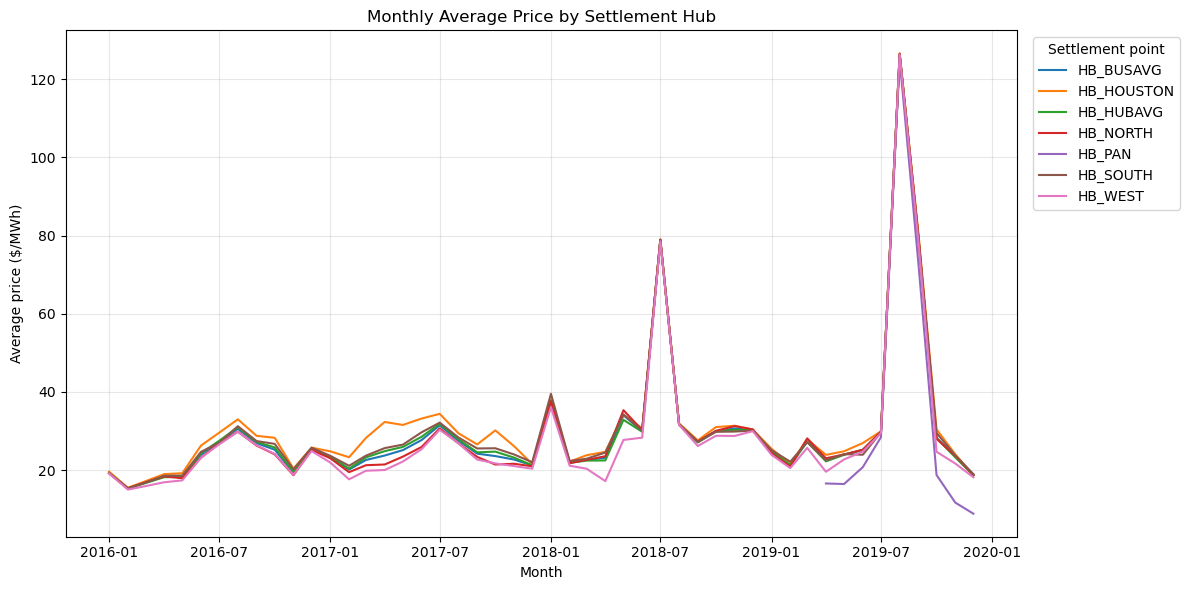

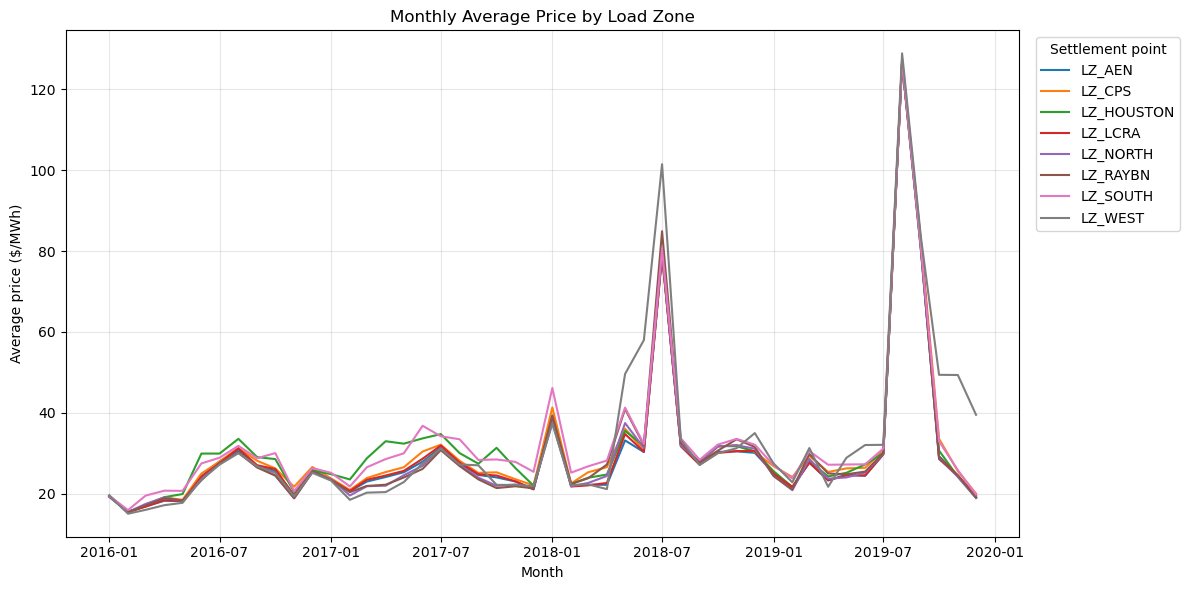

In [16]:
plot_data = monthly_avg.assign(
    Date=pd.to_datetime(dict(year=monthly_avg["Year"], month=monthly_avg["Month"], day=1))
)


def plot_monthly_averages(prefix, title, filename):
    subset = plot_data[plot_data["SettlementPoint"].str.startswith(prefix)]
    fig, ax = plt.subplots(figsize=(12, 6))
    for point, df in subset.groupby("SettlementPoint"):
        ax.plot(df["Date"], df["AveragePrice"], label=point)
    ax.set_title(title)
    ax.set_xlabel("Month")
    ax.set_ylabel("Average price ($/MWh)")
    ax.grid(alpha=0.3)
    ax.legend(title="Settlement point", bbox_to_anchor=(1.01, 1), loc="upper left")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=150)
    plt.show()


plot_monthly_averages("HB_", "Monthly Average Price by Settlement Hub", "SettlementHubAveragePriceByMonth.png")
plot_monthly_averages("LZ_", "Monthly Average Price by Load Zone", "LoadZoneAveragePriceByMonth.png")

## Bonus: Volatility plots
HB_PAN only has data from April 2019, so it appears in 2019 only.

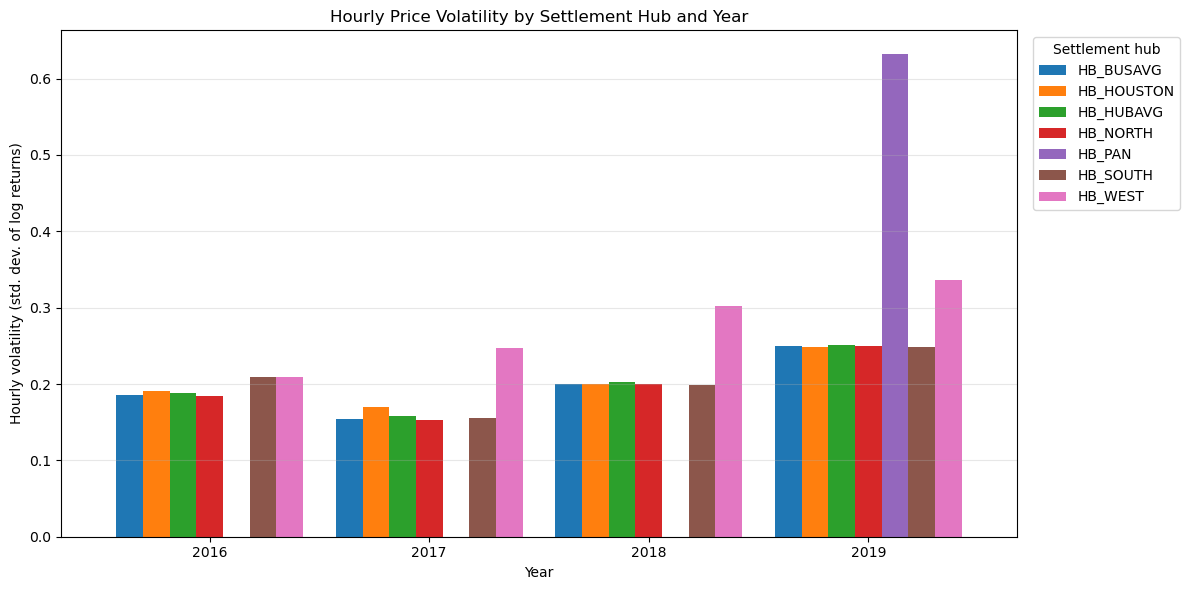

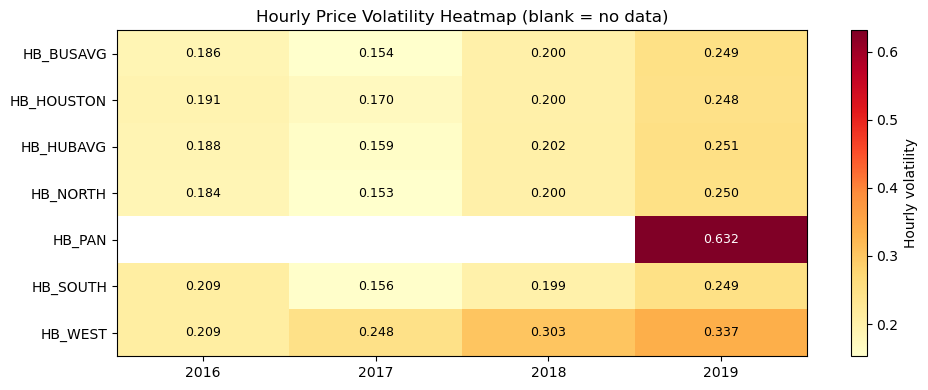

In [17]:
vol_wide = volatility.to_pandas().pivot(index="Year", columns="SettlementPoint", values="HourlyVolatility")

# Grouped bars: hubs side by side within each year
ax = vol_wide.plot.bar(figsize=(12, 6), width=0.85, rot=0)
ax.set_title("Hourly Price Volatility by Settlement Hub and Year")
ax.set_xlabel("Year")
ax.set_ylabel("Hourly volatility (std. dev. of log returns)")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Settlement hub", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "HubVolatilityByYear_Bars.png", dpi=150)
plt.show()

# Heatmap: easier to read exact values and spot the highest per year
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(vol_wide.T.values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(len(vol_wide.index)), vol_wide.index)
ax.set_yticks(range(len(vol_wide.columns)), vol_wide.columns)
for i, hub in enumerate(vol_wide.columns):
    for j, year in enumerate(vol_wide.index):
        value = vol_wide.loc[year, hub]
        if pd.notna(value):
            ax.text(j, i, f"{value:.3f}", ha="center", va="center", fontsize=9,
                    color="white" if value > 0.45 else "black")
ax.set_title("Hourly Price Volatility Heatmap (blank = no data)")
fig.colorbar(im, ax=ax, label="Hourly volatility")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "HubVolatilityByYear_Heatmap.png", dpi=150)
plt.show()

## Bonus: Hourly shape profiles
For each settlement point, month of year and day of week: average price by hour of day, divided by the mean of those 24 hourly averages so each profile averages exactly 1. Columns: `SettlementPoint, Month (1-12), DayOfWeek (1=Monday ... 7=Sunday), X1..X24` (X1 = hour beginning 00:00). HB_PAN has no data for January-March, so it has 63 profiles rather than 84.

In [18]:
PROFILE_DIR = OUTPUT_DIR / "hourlyShapeProfiles"
PROFILE_DIR.mkdir(exist_ok=True)

shape_input = prices.assign(
    Month=prices["Date"].dt.month,
    DayOfWeek=prices["Date"].dt.dayofweek + 1,
    Hour="X" + (prices["Date"].dt.hour + 1).astype(str),
)

hourly_means = shape_input.pivot_table(
    index=["SettlementPoint", "Month", "DayOfWeek"], columns="Hour", values="Price", aggfunc="mean"
)[x_cols]

# Normalise each profile by the mean of its 24 hourly averages
profiles = hourly_means.div(hourly_means.mean(axis=1), axis=0).reset_index()

for point, df in profiles.groupby("SettlementPoint"):
    df.to_csv(PROFILE_DIR / f"profile_{point}.csv", index=False)

print(len(list(PROFILE_DIR.glob("*.csv"))), "files written;", profiles.groupby("SettlementPoint").size().unique(), "profiles per point")
print("Profile means within 1e-9 of 1:", ((profiles[x_cols].mean(axis=1) - 1).abs() < 1e-9).all())
print("Any missing values:", profiles[x_cols].isna().any().any())
profiles.head(3)

15 files written; [84 63] profiles per point
Profile means within 1e-9 of 1: True
Any missing values: False


Hour,SettlementPoint,Month,DayOfWeek,X1,X2,X3,X4,X5,X6,X7,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,X24
0,HB_BUSAVG,1,1,0.761318,0.731616,0.728403,0.751078,0.816122,0.923350,1.533361,...,0.878693,0.860317,0.897231,1.316132,1.393774,1.121186,1.047913,0.980373,0.898016,0.815267
1,HB_BUSAVG,1,2,0.631926,0.600105,0.602633,0.635738,0.726775,0.873789,1.577967,...,0.840368,0.845840,0.902449,1.479425,1.655474,1.244534,1.101036,1.003204,0.887951,0.817417
2,HB_BUSAVG,1,3,0.570807,0.550861,0.553741,0.578395,0.688318,1.059226,3.461336,...,0.653576,0.643916,0.666437,0.943955,1.027715,0.839183,0.789540,0.727219,0.661378,0.601495


## Bonus: Open-ended analysis - predicting LZ_WEST from the other load zones
LZ_WEST is the load zone that diverges most from the rest during price spikes (see the load zone plot), so it is the interesting one to predict. Features are the hourly prices of the other 7 load zones plus hour and month; hubs are excluded to avoid near-duplicates of the target (e.g. HB_WEST). Train on 2016-2018, test on 2019 (a time-based split, so no future data leaks into training).

In [19]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

TARGET = "LZ_WEST"
zones = prices[prices["SettlementPoint"].str.startswith("LZ_")].pivot(index="Date", columns="SettlementPoint", values="Price")
features = zones.drop(columns=TARGET).assign(Hour=zones.index.hour, Month=zones.index.month)
target = zones[TARGET]

train = features.index.year <= 2018
X_train, X_test, y_train, y_test = features[train], features[~train], target[train], target[~train]

models = {
    "Linear regression": LinearRegression(),
    "Gradient boosting": HistGradientBoostingRegressor(random_state=0),
}
results, predictions = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = pd.Series(model.predict(X_test), index=X_test.index)
    results.append({
        "Model": name,
        "R2": r2_score(y_test, predictions[name]),
        "MAE ($/MWh)": mean_absolute_error(y_test, predictions[name]),
    })
pd.DataFrame(results).round(3)

,Model,R2,MAE ($/MWh)
0,Linear regression,0.988,8.748
1,Gradient boosting,0.126,20.630


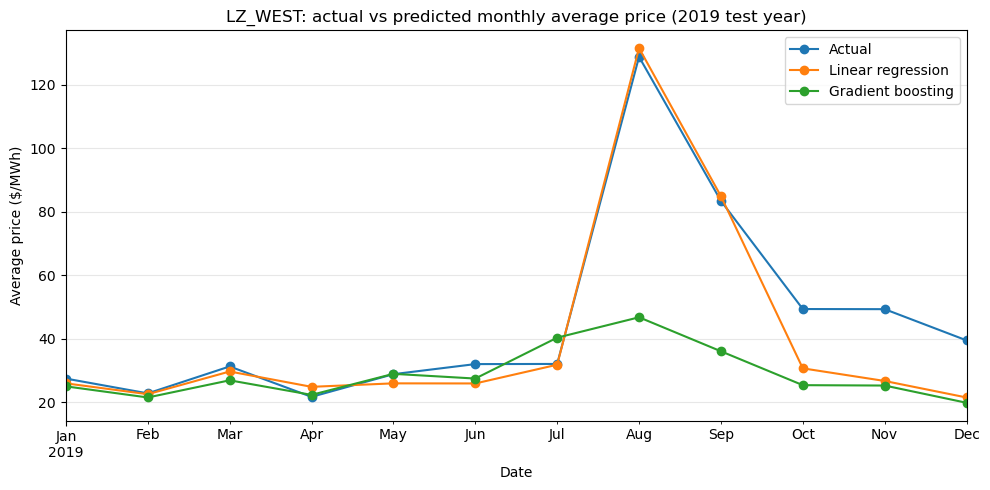

Max price in train: 2151.82 | max price in test: 5015.25


In [20]:
# Compare actual vs predicted as monthly averages over the 2019 test year
monthly = pd.DataFrame({"Actual": y_test, **predictions}).resample("MS").mean()
ax = monthly.plot(figsize=(10, 5), marker="o")
ax.set_title(f"{TARGET}: actual vs predicted monthly average price (2019 test year)")
ax.set_ylabel("Average price ($/MWh)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "LZ_WEST_Prediction_2019.png", dpi=150)
plt.show()

# Does the gradient boosting model see prices outside its training range?
print("Max price in train:", y_train.max(), "| max price in test:", y_test.max())